In [27]:
from torch.utils.data import Dataset
import numpy as np
from scripts.data import load_lfw, make_splits, SEED
from torchvision import transforms
from PIL import Image
from torchvision.transforms.functional import to_pil_image
import torch

In [13]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
IMG_SIZE = 112

In [11]:
def get_transforms(train: bool):
    if train:
        return transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(10),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
            transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])
    return transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])

In [7]:
class TripletDataset(Dataset):
    def __init__(self, images, labels, train: bool = True):
        self.images = images
        self.labels = labels
        self.transform = get_transforms(train)
        self.class_to_indices = {
            c: np.where(labels == c)[0] for c in np.unique(labels)
        }
        self.classes = np.array(list(self.class_to_indices))
        self.rng = np.random.default_rng(SEED)

    def __len__(self):
        return len(self.labels)

    def _load(self, i):
        return self.transform(Image.fromarray(self.images[i]))

    def __getitem__(self, i):
        anchor_label = self.labels[i]
        pos_pool = self.class_to_indices[anchor_label]
        pos = i
        while pos == i and len(pos_pool) > 1:
            pos = int(self.rng.choice(pos_pool))
        neg_label = anchor_label
        while neg_label == anchor_label:
            neg_label = int(self.rng.choice(self.classes))
        neg = int(self.rng.choice(self.class_to_indices[neg_label]))
        return self._load(i), self._load(pos), self._load(neg)

In [8]:
images, labels, class_names = load_lfw()
train_idx, val_idx, _ = make_splits(labels)

In [16]:
train_ds = TripletDataset(images[train_idx], labels[train_idx], train=True)
val_ds = TripletDataset(images[val_idx], labels[val_idx], train=False)

In [38]:
len(train_ds), len(val_ds)

(2116, 453)

In [22]:
len(train_ds[0])

3

In [23]:
anchor, positive, negative = train_ds[0]

In [25]:
anchor.shape, positive.shape, negative.shape

(torch.Size([3, 112, 112]),
 torch.Size([3, 112, 112]),
 torch.Size([3, 112, 112]))

In [28]:
def tensor_to_pil(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    tensor = (tensor.cpu() * std + mean).clamp(0, 1)
    return to_pil_image(tensor)

In [29]:
anchor_pil = tensor_to_pil(anchor)
positive_pil = tensor_to_pil(positive)
negative_pil = tensor_to_pil(negative)

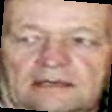

In [30]:
anchor_pil

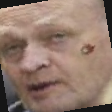

In [31]:
positive_pil

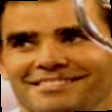

In [32]:
negative_pil

In [33]:
anchor, positive, negative = train_ds[1]

In [34]:
anchor_pil = tensor_to_pil(anchor)
positive_pil = tensor_to_pil(positive)
negative_pil = tensor_to_pil(negative)

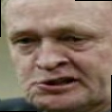

In [35]:
anchor_pil

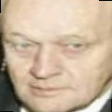

In [36]:
positive_pil

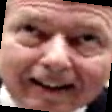

In [37]:
negative_pil